## ML Assignment 2 – Email Spam Detection

Binary Classification using K-Nearest Neighbors (KNN) & Support Vector Machine (SVM)

Classify emails into two states:
- Normal State (0) – Not Spam  
- Abnormal State (1) – Spam 

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Classifiers
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc,
    ConfusionMatrixDisplay
)

# Plot settings
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid', palette='muted')

print("All libraries imported successfully!")

All libraries imported successfully!



## 2. Load and Explore the Dataset

In [2]:
# Load dataset
df = pd.read_csv('emails.csv')

print(f"Dataset Shape: {df.shape}")
print(f"Number of emails  : {df.shape[0]}")
print(f"Number of features: {df.shape[1] - 2}  (excluding Email No. and Prediction)")
print("\nFirst 5 rows:")
df.head()

Dataset Shape: (5172, 3002)
Number of emails  : 5172
Number of features: 3000  (excluding Email No. and Prediction)

First 5 rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [3]:
# Basic information
print("Dataset Info:")
print(f"  Columns  : {df.shape[1]}")
print(f"  Data types:\n{df.dtypes.value_counts()}")
print(f"\nMissing values: {df.isnull().sum().sum()}")

Dataset Info:
  Columns  : 3002
  Data types:
int64    3001
str         1
Name: count, dtype: int64

Missing values: 0


Target Class Distribution:
  Not Spam (0): 3672  (71.0%)
  Spam     (1): 1500  (29.0%)


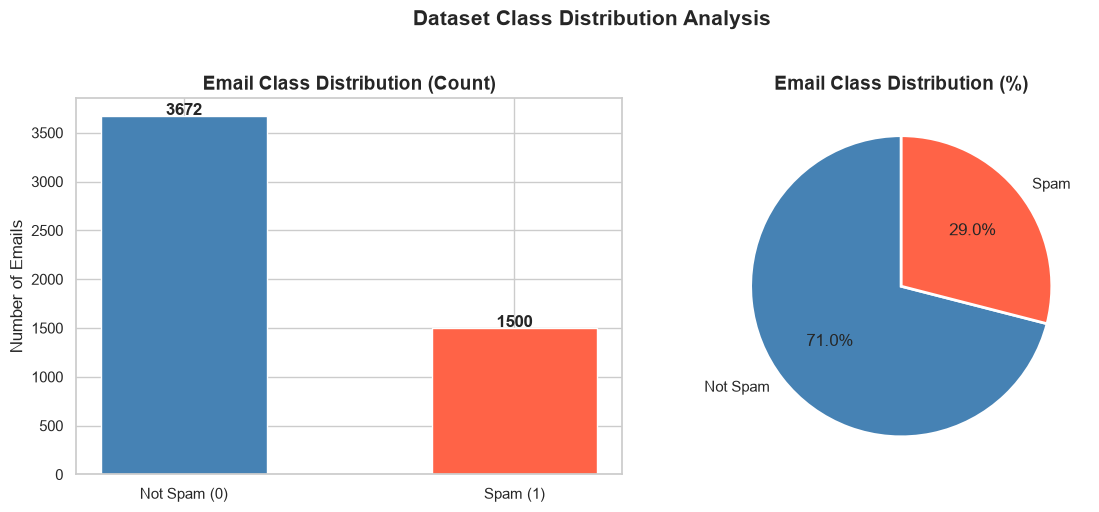

In [4]:
# Target class distribution
class_counts = df['Prediction'].value_counts()
print("Target Class Distribution:")
print(f"  Not Spam (0): {class_counts[0]}  ({class_counts[0]/len(df)*100:.1f}%)")
print(f"  Spam     (1): {class_counts[1]}  ({class_counts[1]/len(df)*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
axes[0].bar(['Not Spam (0)', 'Spam (1)'], class_counts.values,
            color=['steelblue', 'tomato'], edgecolor='white', width=0.5)
axes[0].set_title('Email Class Distribution (Count)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Emails')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(class_counts.values, labels=['Not Spam', 'Spam'],
            autopct='%1.1f%%', colors=['steelblue', 'tomato'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Email Class Distribution (%)', fontsize=14, fontweight='bold')

plt.suptitle('Dataset Class Distribution Analysis', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Exploratory Data Analysis (EDA)

In [5]:
# Descriptive statistics of target classes
feature_cols = df.columns[1:-1]  # exclude 'Email No.' and 'Prediction'
print(f"Total feature words: {len(feature_cols)}")
print("\nSample feature column names:")
print(list(feature_cols[:20]))

Total feature words: 3000

Sample feature column names:
['the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou', 'in', 'on', 'is', 'this', 'enron', 'i', 'be', 'that', 'will', 'have', 'with']


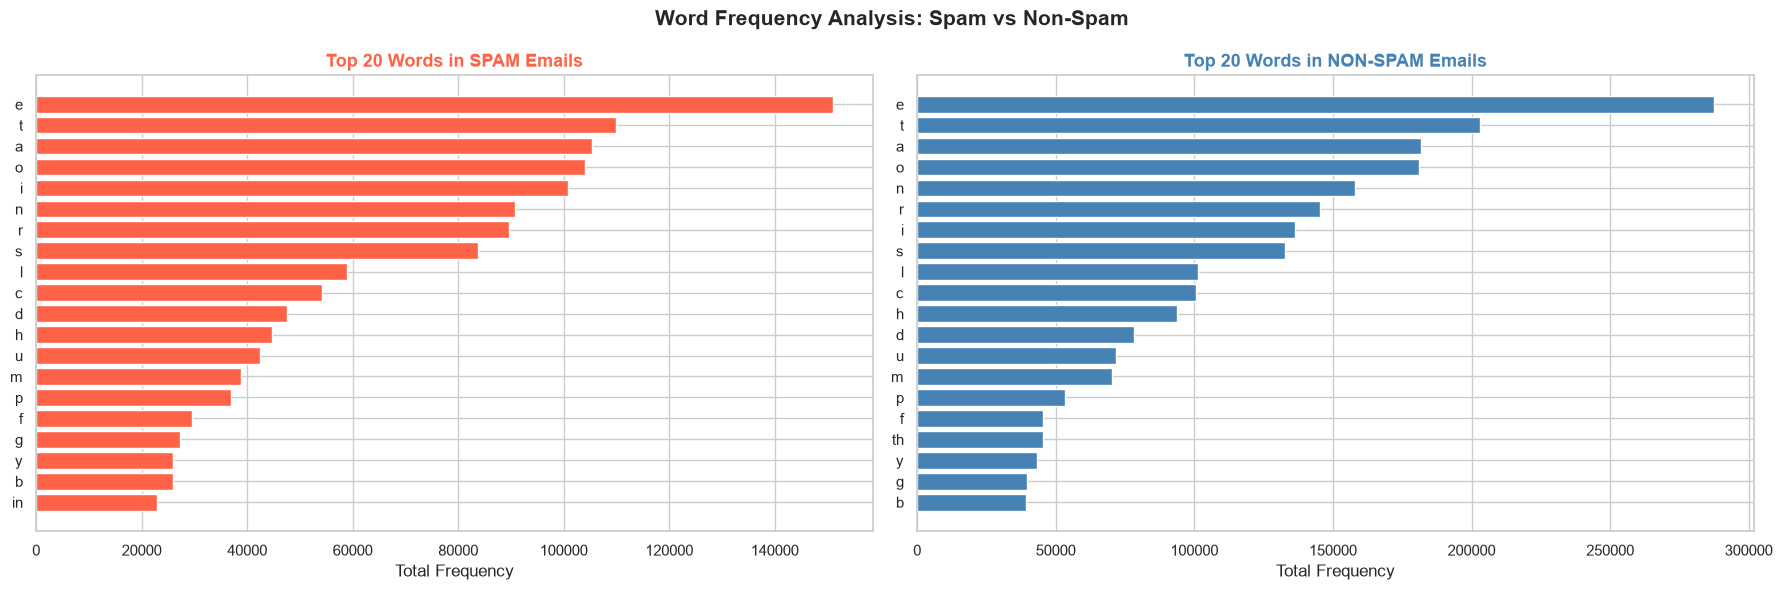

In [6]:
# Top 20 most frequent words in Spam vs Non-Spam emails
spam_df    = df[df['Prediction'] == 1][feature_cols]
nonspam_df = df[df['Prediction'] == 0][feature_cols]

spam_freq    = spam_df.sum().sort_values(ascending=False).head(20)
nonspam_freq = nonspam_df.sum().sort_values(ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].barh(spam_freq.index[::-1], spam_freq.values[::-1], color='tomato', edgecolor='white')
axes[0].set_title('Top 20 Words in SPAM Emails', fontsize=13, fontweight='bold', color='tomato')
axes[0].set_xlabel('Total Frequency')

axes[1].barh(nonspam_freq.index[::-1], nonspam_freq.values[::-1], color='steelblue', edgecolor='white')
axes[1].set_title('Top 20 Words in NON-SPAM Emails', fontsize=13, fontweight='bold', color='steelblue')
axes[1].set_xlabel('Total Frequency')

plt.suptitle('Word Frequency Analysis: Spam vs Non-Spam', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
# Average word frequency per email by class
avg_words_spam    = spam_df.sum(axis=1).mean()
avg_words_nonspam = nonspam_df.sum(axis=1).mean()

print(f"Average total word count in Spam emails    : {avg_words_spam:.1f}")
print(f"Average total word count in Non-Spam emails: {avg_words_nonspam:.1f}")

# Feature sparsity
total_features = len(feature_cols)
zero_pct = (df[feature_cols] == 0).sum().sum() / (len(df) * total_features) * 100
print(f"\nFeature matrix sparsity: {zero_pct:.1f}% zeros")

Average total word count in Spam emails    : 1458.8
Average total word count in Non-Spam emails: 1045.4

Feature matrix sparsity: 94.4% zeros



## 4. Data Preprocessing

In [8]:
# Separate features (X) and target (y)
X = df[feature_cols].values
y = df['Prediction'].values

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape : {y.shape}")
print(f"Class labels        : {np.unique(y)}  (0 = Not Spam, 1 = Spam)")

Feature matrix shape: (5172, 3000)
Target vector shape : (5172,)
Class labels        : [0 1]  (0 = Not Spam, 1 = Spam)


In [9]:
# Train-Test Split (80:20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set  : {X_train.shape[0]} samples")
print(f"Testing set   : {X_test.shape[0]} samples")
print(f"\nTrain class distribution - Not Spam: {(y_train==0).sum()}, Spam: {(y_train==1).sum()}")
print(f"Test  class distribution - Not Spam: {(y_test==0).sum()},  Spam: {(y_test==1).sum()}")

Training set  : 4137 samples
Testing set   : 1035 samples

Train class distribution - Not Spam: 2937, Spam: 1200
Test  class distribution - Not Spam: 735,  Spam: 300


In [10]:
# Feature Scaling (StandardScaler)
# Important for both KNN (distance-based) and SVM (margin-based)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Feature scaling applied successfully (StandardScaler).")
print(f"  Train mean (post-scale): {X_train_scaled.mean():.4f}")
print(f"  Train std  (post-scale): {X_train_scaled.std():.4f}")

Feature scaling applied successfully (StandardScaler).
  Train mean (post-scale): 0.0000
  Train std  (post-scale): 1.0000



## 5. K-Nearest Neighbors (KNN) Classifier

### 5.1 Finding the Optimal K

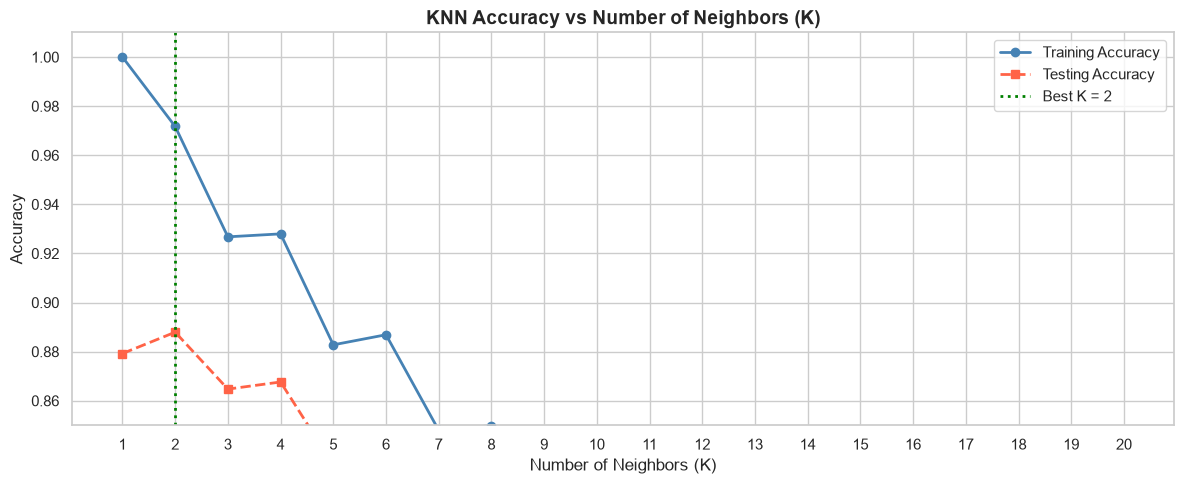

Best K = 2 with Test Accuracy = 88.79%


In [11]:
# Elbow Method: Test different K values
k_range = range(1, 21)
knn_train_scores = []
knn_test_scores  = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    knn.fit(X_train_scaled, y_train)
    knn_train_scores.append(knn.score(X_train_scaled, y_train))
    knn_test_scores.append(knn.score(X_test_scaled, y_test))

# Plot
plt.figure(figsize=(12, 5))
plt.plot(k_range, knn_train_scores, 'o-', color='steelblue', label='Training Accuracy', linewidth=2)
plt.plot(k_range, knn_test_scores,  's--', color='tomato',    label='Testing Accuracy',  linewidth=2)
best_k = k_range[np.argmax(knn_test_scores)]
plt.axvline(x=best_k, color='green', linestyle=':', linewidth=2, label=f'Best K = {best_k}')
plt.title('KNN Accuracy vs Number of Neighbors (K)', fontsize=14, fontweight='bold')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.legend()
plt.xticks(k_range)
plt.ylim(0.85, 1.01)
plt.tight_layout()
plt.show()

print(f"Best K = {best_k} with Test Accuracy = {max(knn_test_scores)*100:.2f}%")

### 5.2 Train KNN with Best K

In [12]:
# Train KNN with best K
knn_best = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn_best.fit(X_train_scaled, y_train)

# Predictions
y_pred_knn_train = knn_best.predict(X_train_scaled)
y_pred_knn_test  = knn_best.predict(X_test_scaled)

print(f"KNN (K={best_k}) – Performance Summary")
print("="*45)
print(f"  Train Accuracy : {accuracy_score(y_train, y_pred_knn_train)*100:.2f}%")
print(f"  Test  Accuracy : {accuracy_score(y_test, y_pred_knn_test)*100:.2f}%")
print(f"  Precision      : {precision_score(y_test, y_pred_knn_test)*100:.2f}%")
print(f"  Recall         : {recall_score(y_test, y_pred_knn_test)*100:.2f}%")
print(f"  F1-Score       : {f1_score(y_test, y_pred_knn_test)*100:.2f}%")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_knn_test, target_names=['Not Spam', 'Spam']))

KNN (K=2) – Performance Summary
  Train Accuracy : 97.17%
  Test  Accuracy : 88.79%
  Precision      : 80.07%
  Recall         : 81.67%
  F1-Score       : 80.86%

Detailed Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.92      0.92      0.92       735
        Spam       0.80      0.82      0.81       300

    accuracy                           0.89      1035
   macro avg       0.86      0.87      0.86      1035
weighted avg       0.89      0.89      0.89      1035



### 5.3 KNN Confusion Matrix

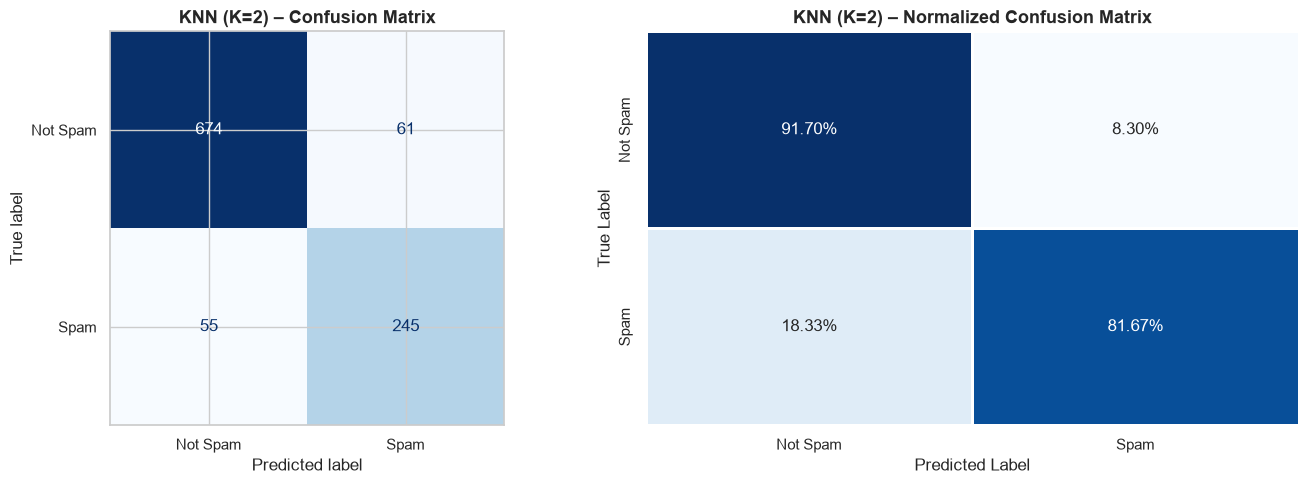

True Negatives  (Correctly classified Not Spam): 674
True Positives  (Correctly classified Spam)    : 245
False Positives (Not Spam classified as Spam)  : 61
False Negatives (Spam classified as Not Spam)  : 55


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix (counts)
cm_knn = confusion_matrix(y_test, y_pred_knn_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=['Not Spam', 'Spam'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'KNN (K={best_k}) – Confusion Matrix', fontsize=13, fontweight='bold')

# Confusion Matrix (normalized)
cm_knn_norm = cm_knn.astype('float') / cm_knn.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_knn_norm, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'],
            linewidths=1, ax=axes[1], cbar=False)
axes[1].set_title(f'KNN (K={best_k}) – Normalized Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_knn.ravel()
print(f"True Negatives  (Correctly classified Not Spam): {tn}")
print(f"True Positives  (Correctly classified Spam)    : {tp}")
print(f"False Positives (Not Spam classified as Spam)  : {fp}")
print(f"False Negatives (Spam classified as Not Spam)  : {fn}")


## 6. Support Vector Machine (SVM) Classifier

### 6.1 SVM with Different Kernels

In [14]:
# Compare different SVM kernels
kernels = ['linear', 'rbf', 'poly', 'sigmoid']
kernel_results = {}

print("SVM Kernel Comparison:")
print("-" * 55)
print(f"{'Kernel':<12} {'Train Acc':>10} {'Test Acc':>10} {'F1-Score':>10}")
print("-" * 55)

for kernel in kernels:
    svm_temp = SVC(kernel=kernel, C=1.0, random_state=42)
    svm_temp.fit(X_train_scaled, y_train)
    y_pred_temp = svm_temp.predict(X_test_scaled)
    train_acc = accuracy_score(y_train, svm_temp.predict(X_train_scaled))
    test_acc  = accuracy_score(y_test, y_pred_temp)
    f1        = f1_score(y_test, y_pred_temp)
    kernel_results[kernel] = {'train_acc': train_acc, 'test_acc': test_acc, 'f1': f1}
    print(f"{kernel:<12} {train_acc*100:>9.2f}% {test_acc*100:>9.2f}% {f1*100:>9.2f}%")

print("-" * 55)
best_kernel = max(kernel_results, key=lambda x: kernel_results[x]['test_acc'])
print(f"\nBest Kernel: '{best_kernel}' with Test Accuracy = {kernel_results[best_kernel]['test_acc']*100:.2f}%")

SVM Kernel Comparison:
-------------------------------------------------------
Kernel        Train Acc   Test Acc   F1-Score
-------------------------------------------------------
linear           99.98%     95.07%     91.51%
rbf              96.83%     93.04%     86.57%
poly             78.54%     75.94%     30.64%
sigmoid          91.23%     87.54%     76.50%
-------------------------------------------------------

Best Kernel: 'linear' with Test Accuracy = 95.07%


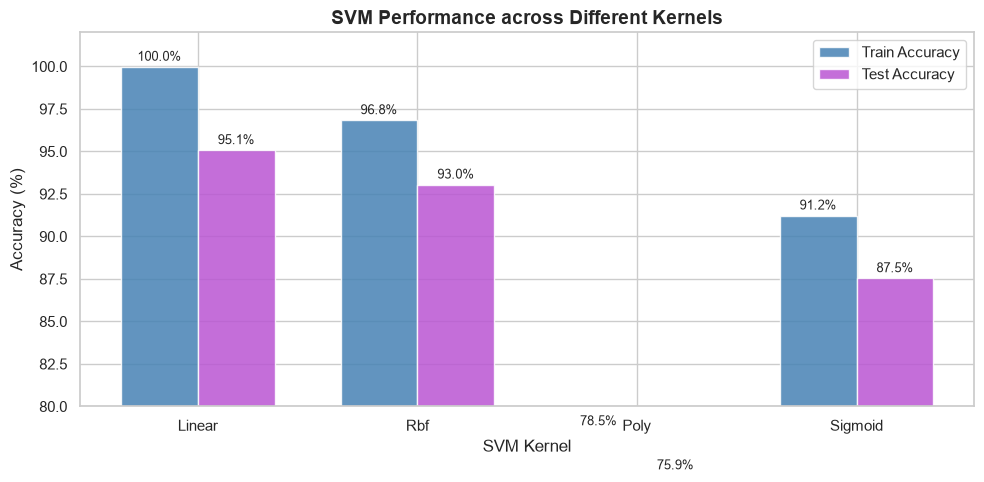

In [15]:
# Visualize kernel comparison
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(kernels))
width = 0.35

train_accs = [kernel_results[k]['train_acc']*100 for k in kernels]
test_accs  = [kernel_results[k]['test_acc']*100  for k in kernels]

bars1 = ax.bar(x - width/2, train_accs, width, label='Train Accuracy', color='steelblue',   alpha=0.85, edgecolor='white')
bars2 = ax.bar(x + width/2, test_accs,  width, label='Test Accuracy',  color='mediumorchid', alpha=0.85, edgecolor='white')

ax.set_xlabel('SVM Kernel')
ax.set_ylabel('Accuracy (%)')
ax.set_title('SVM Performance across Different Kernels', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([k.capitalize() for k in kernels])
ax.legend()
ax.set_ylim(80, 102)

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### 6.2 Train Best SVM Model

In [16]:
# Train best SVM model
svm_best = SVC(kernel=best_kernel, C=1.0, random_state=42, probability=True)
svm_best.fit(X_train_scaled, y_train)

# Predictions
y_pred_svm_train = svm_best.predict(X_train_scaled)
y_pred_svm_test  = svm_best.predict(X_test_scaled)

print(f"SVM (Kernel={best_kernel}) – Performance Summary")
print("="*48)
print(f"  Train Accuracy : {accuracy_score(y_train, y_pred_svm_train)*100:.2f}%")
print(f"  Test  Accuracy : {accuracy_score(y_test, y_pred_svm_test)*100:.2f}%")
print(f"  Precision      : {precision_score(y_test, y_pred_svm_test)*100:.2f}%")
print(f"  Recall         : {recall_score(y_test, y_pred_svm_test)*100:.2f}%")
print(f"  F1-Score       : {f1_score(y_test, y_pred_svm_test)*100:.2f}%")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_svm_test, target_names=['Not Spam', 'Spam']))

SVM (Kernel=linear) – Performance Summary
  Train Accuracy : 99.98%
  Test  Accuracy : 95.07%
  Precision      : 91.36%
  Recall         : 91.67%
  F1-Score       : 91.51%

Detailed Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



### 6.3 SVM Confusion Matrix

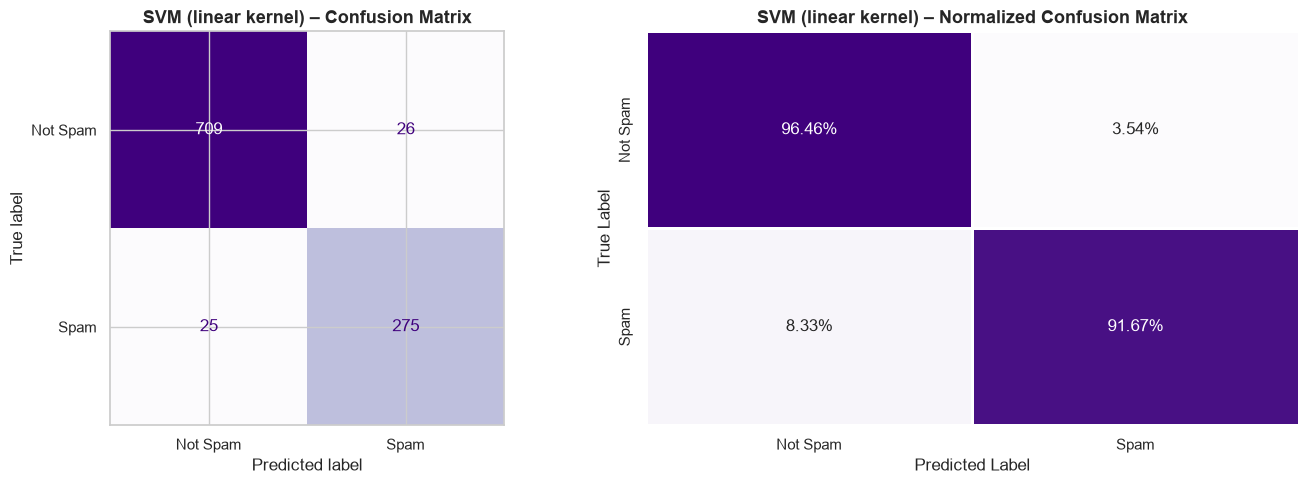

True Negatives  (Correctly classified Not Spam): 709
True Positives  (Correctly classified Spam)    : 275
False Positives (Not Spam classified as Spam)  : 26
False Negatives (Spam classified as Not Spam)  : 25


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_svm = confusion_matrix(y_test, y_pred_svm_test)
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=['Not Spam', 'Spam'])
disp_svm.plot(ax=axes[0], cmap='Purples', colorbar=False)
axes[0].set_title(f'SVM ({best_kernel} kernel) – Confusion Matrix', fontsize=13, fontweight='bold')

cm_svm_norm = cm_svm.astype('float') / cm_svm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_svm_norm, annot=True, fmt='.2%', cmap='Purples',
            xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'],
            linewidths=1, ax=axes[1], cbar=False)
axes[1].set_title(f'SVM ({best_kernel} kernel) – Normalized Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

tn_s, fp_s, fn_s, tp_s = cm_svm.ravel()
print(f"True Negatives  (Correctly classified Not Spam): {tn_s}")
print(f"True Positives  (Correctly classified Spam)    : {tp_s}")
print(f"False Positives (Not Spam classified as Spam)  : {fp_s}")
print(f"False Negatives (Spam classified as Not Spam)  : {fn_s}")


## 7. ROC Curve & AUC Comparison

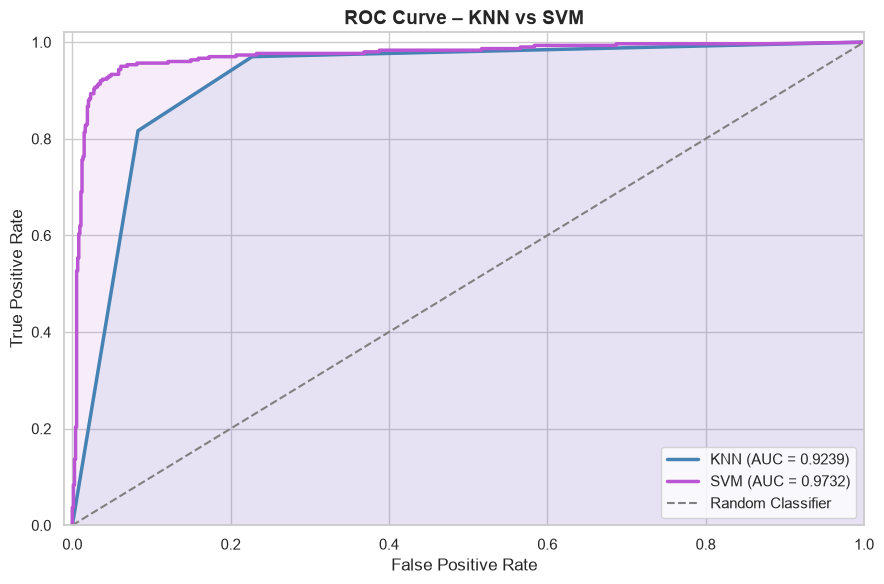

AUC – KNN: 0.9239
AUC – SVM: 0.9732


In [18]:
# ROC Curves – KNN vs SVM
# KNN probabilities
y_prob_knn = knn_best.predict_proba(X_test_scaled)[:, 1]
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
auc_knn = auc(fpr_knn, tpr_knn)

# SVM probabilities
y_prob_svm = svm_best.predict_proba(X_test_scaled)[:, 1]
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = auc(fpr_svm, tpr_svm)

plt.figure(figsize=(9, 6))
plt.plot(fpr_knn, tpr_knn, color='steelblue',    lw=2.5, label=f'KNN (AUC = {auc_knn:.4f})')
plt.plot(fpr_svm, tpr_svm, color='mediumorchid', lw=2.5, label=f'SVM (AUC = {auc_svm:.4f})')
plt.plot([0, 1], [0, 1],   color='gray',         lw=1.5, linestyle='--', label='Random Classifier')

plt.fill_between(fpr_knn, tpr_knn, alpha=0.10, color='steelblue')
plt.fill_between(fpr_svm, tpr_svm, alpha=0.10, color='mediumorchid')

plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve – KNN vs SVM', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

print(f"AUC – KNN: {auc_knn:.4f}")
print(f"AUC – SVM: {auc_svm:.4f}")


## 8. Cross-Validation Analysis

In [19]:
# 5-Fold Cross Validation for both models
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=best_k))
])

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel=best_kernel, C=1.0, random_state=42))
])

cv_knn = cross_val_score(knn_pipeline, X, y, cv=5, scoring='accuracy')
cv_svm = cross_val_score(svm_pipeline, X, y, cv=5, scoring='accuracy')

print("5-Fold Cross-Validation Results:")
print("-" * 50)
print(f"KNN  : {cv_knn}")
print(f"  Mean ± Std: {cv_knn.mean()*100:.2f}% ± {cv_knn.std()*100:.2f}%")
print()
print(f"SVM  : {cv_svm}")
print(f"  Mean ± Std: {cv_svm.mean()*100:.2f}% ± {cv_svm.std()*100:.2f}%")

5-Fold Cross-Validation Results:
--------------------------------------------------
KNN  : [0.83574879 0.88405797 0.8655706  0.87427466 0.82978723]
  Mean ± Std: 85.79% ± 2.14%

SVM  : [0.9294686  0.9468599  0.94197292 0.93810445 0.91005803]
  Mean ± Std: 93.33% ± 1.29%


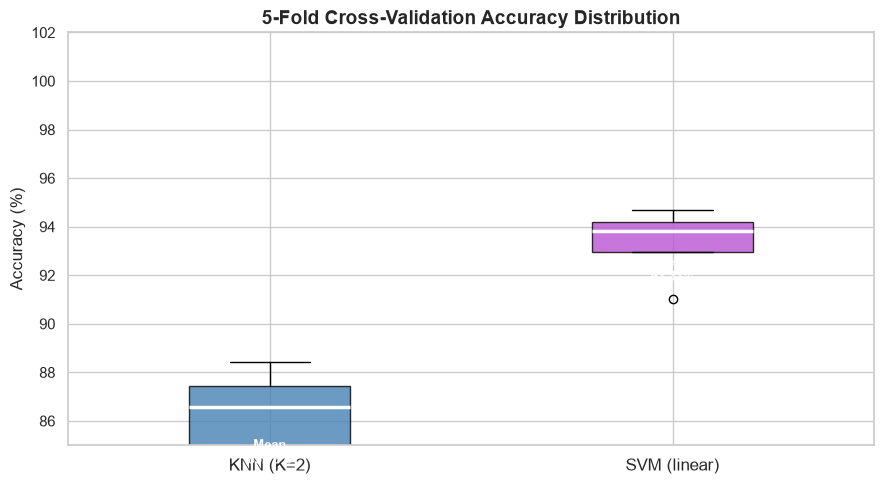

In [20]:
# Boxplot of cross-validation scores
fig, ax = plt.subplots(figsize=(9, 5))

cv_data = [cv_knn * 100, cv_svm * 100]
bp = ax.boxplot(cv_data, patch_artist=True, notch=False, widths=0.4,
                medianprops=dict(color='white', linewidth=2.5))

colors = ['steelblue', 'mediumorchid']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax.set_xticklabels([f'KNN (K={best_k})', f'SVM ({best_kernel})'], fontsize=12)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_title('5-Fold Cross-Validation Accuracy Distribution', fontsize=14, fontweight='bold')
ax.set_ylim(85, 102)

# Add mean annotation
for i, scores in enumerate([cv_knn, cv_svm], start=1):
    ax.text(i, scores.mean()*100 - 0.5, f'Mean\n{scores.mean()*100:.2f}%',
            ha='center', va='top', fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()


## 9. Performance Comparison: KNN vs SVM

In [21]:
# Build comprehensive comparison table
metrics = {
    'Metric': ['Accuracy', 'Precision', 'Recall (Sensitivity)', 'F1-Score', 'AUC-ROC', 'CV Mean Accuracy'],
    f'KNN (K={best_k})': [
        f"{accuracy_score(y_test, y_pred_knn_test)*100:.2f}%",
        f"{precision_score(y_test, y_pred_knn_test)*100:.2f}%",
        f"{recall_score(y_test, y_pred_knn_test)*100:.2f}%",
        f"{f1_score(y_test, y_pred_knn_test)*100:.2f}%",
        f"{auc_knn:.4f}",
        f"{cv_knn.mean()*100:.2f}%"
    ],
    f'SVM ({best_kernel})': [
        f"{accuracy_score(y_test, y_pred_svm_test)*100:.2f}%",
        f"{precision_score(y_test, y_pred_svm_test)*100:.2f}%",
        f"{recall_score(y_test, y_pred_svm_test)*100:.2f}%",
        f"{f1_score(y_test, y_pred_svm_test)*100:.2f}%",
        f"{auc_svm:.4f}",
        f"{cv_svm.mean()*100:.2f}%"
    ]
}

comparison_df = pd.DataFrame(metrics)
comparison_df = comparison_df.set_index('Metric')
print("="*55)
print("     MODEL PERFORMANCE COMPARISON TABLE")
print("="*55)
print(comparison_df.to_string())
print("="*55)

     MODEL PERFORMANCE COMPARISON TABLE
                     KNN (K=2) SVM (linear)
Metric                                     
Accuracy                88.79%       95.07%
Precision               80.07%       91.36%
Recall (Sensitivity)    81.67%       91.67%
F1-Score                80.86%       91.51%
AUC-ROC                 0.9239       0.9732
CV Mean Accuracy        85.79%       93.33%


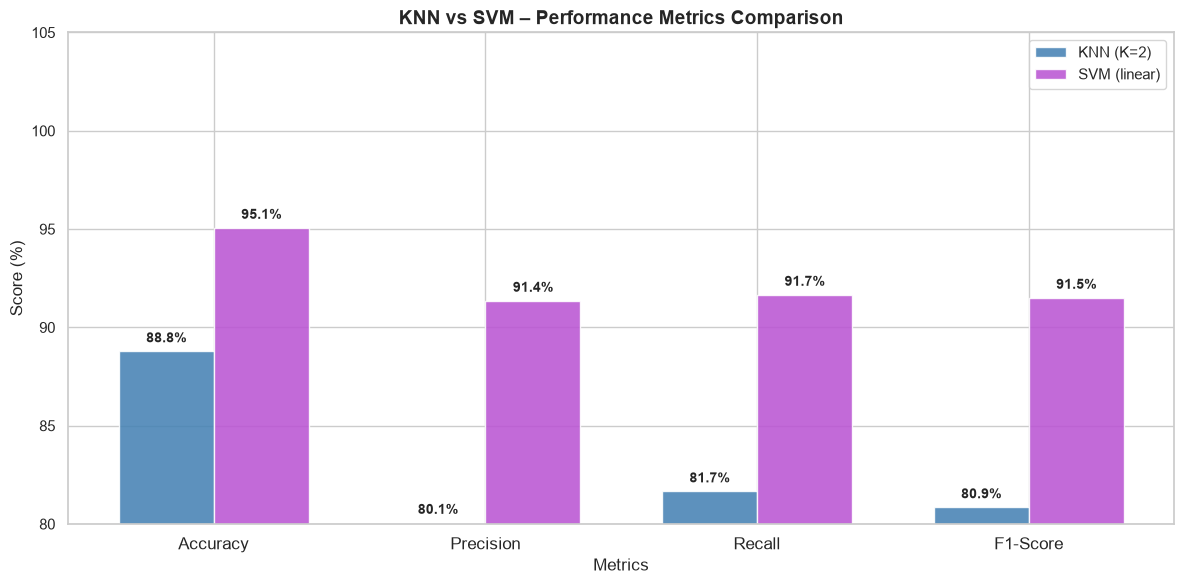

In [22]:
# Visual comparison bar chart
numeric_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
knn_vals = [
    accuracy_score(y_test, y_pred_knn_test)*100,
    precision_score(y_test, y_pred_knn_test)*100,
    recall_score(y_test, y_pred_knn_test)*100,
    f1_score(y_test, y_pred_knn_test)*100
]
svm_vals = [
    accuracy_score(y_test, y_pred_svm_test)*100,
    precision_score(y_test, y_pred_svm_test)*100,
    recall_score(y_test, y_pred_svm_test)*100,
    f1_score(y_test, y_pred_svm_test)*100
]

x = np.arange(len(numeric_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, knn_vals, width, label=f'KNN (K={best_k})',
               color='steelblue', alpha=0.88, edgecolor='white')
bars2 = ax.bar(x + width/2, svm_vals, width, label=f'SVM ({best_kernel})',
               color='mediumorchid', alpha=0.88, edgecolor='white')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.3,
            f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xlabel('Metrics', fontsize=12)
ax.set_ylabel('Score (%)', fontsize=12)
ax.set_title('KNN vs SVM – Performance Metrics Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(numeric_metrics, fontsize=12)
ax.legend(fontsize=11)
ax.set_ylim(80, 105)

plt.tight_layout()
plt.show()


## 10. PCA Visualization (2D Decision Boundary)

Explained Variance Ratio (2 components): [0.07080594 0.02463934]
Total Variance Explained: 9.54%


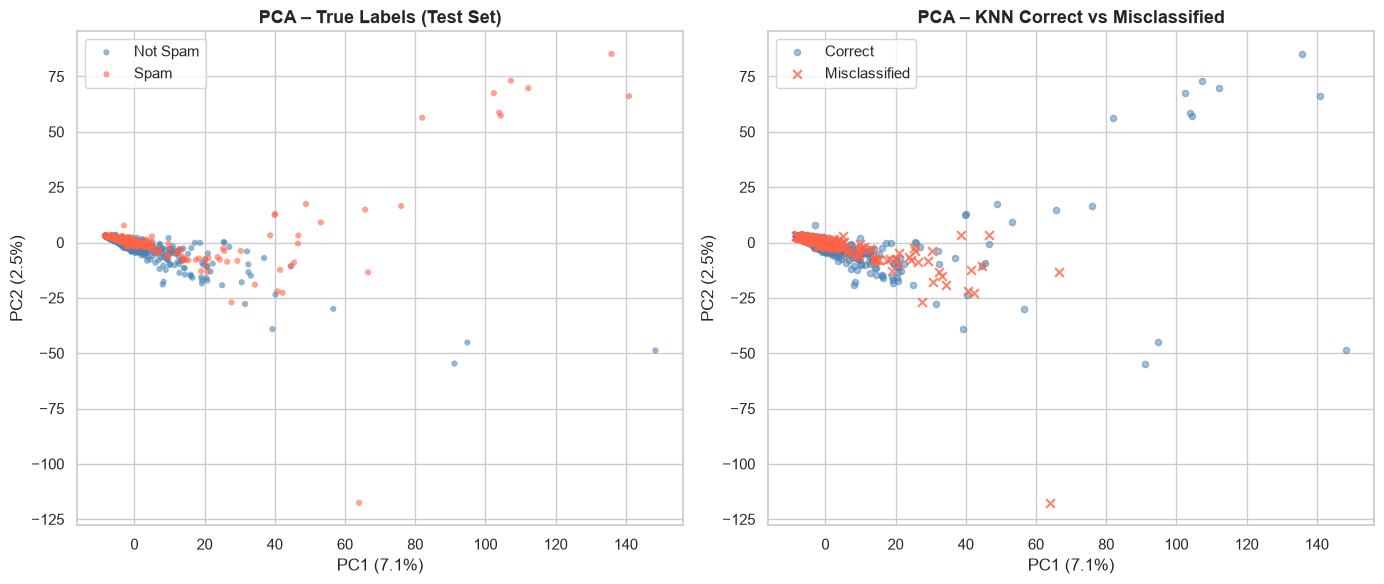

In [23]:
# Reduce dimensions to 2D for visualization using PCA
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f"Explained Variance Ratio (2 components): {pca.explained_variance_ratio_}")
print(f"Total Variance Explained: {sum(pca.explained_variance_ratio_)*100:.2f}%")

# Plot PCA scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = {0: 'steelblue', 1: 'tomato'}
labels = {0: 'Not Spam', 1: 'Spam'}

for cls in [0, 1]:
    mask = y_test == cls
    axes[0].scatter(X_test_pca[mask, 0], X_test_pca[mask, 1],
                    c=colors[cls], label=labels[cls], alpha=0.6, s=20, edgecolors='none')

axes[0].set_title('PCA – True Labels (Test Set)', fontsize=13, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].legend()

# KNN predictions on PCA space
knn_pca = KNeighborsClassifier(n_neighbors=best_k)
knn_pca.fit(X_train_pca, y_train)
y_pred_pca = knn_pca.predict(X_test_pca)

correct = y_pred_pca == y_test
axes[1].scatter(X_test_pca[correct, 0],  X_test_pca[correct, 1],
                c='steelblue', label='Correct', alpha=0.5, s=20)
axes[1].scatter(X_test_pca[~correct, 0], X_test_pca[~correct, 1],
                c='tomato', label='Misclassified', alpha=0.8, s=40, marker='x')

axes[1].set_title('PCA – KNN Correct vs Misclassified', fontsize=13, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].legend()

plt.tight_layout()
plt.show()


## 11. Conclusion & Analysis

In [24]:
# Final summary
knn_acc = accuracy_score(y_test, y_pred_knn_test) * 100
svm_acc = accuracy_score(y_test, y_pred_svm_test) * 100
winner  = 'KNN' if knn_acc > svm_acc else 'SVM'

print("=" * 60)
print("         ASSIGNMENT 2 – CONCLUSION SUMMARY")
print("=" * 60)
print()
print("📌 Problem : Email Spam Detection (Binary Classification)")
print("📌 Dataset : emails.csv  |  5,172 emails  |  3,000+ features")
print("📌 Classes : 0 = Not Spam  |  1 = Spam")
print()
print(f"KNN (K = {best_k}):")
print(f"  - Test Accuracy  : {knn_acc:.2f}%")
print(f"  - AUC-ROC Score  : {auc_knn:.4f}")
print(f"  - CV Accuracy    : {cv_knn.mean()*100:.2f}% ± {cv_knn.std()*100:.2f}%")
print()
print(f"SVM (Kernel = {best_kernel}):")
print(f"  - Test Accuracy  : {svm_acc:.2f}%")
print(f"  - AUC-ROC Score  : {auc_svm:.4f}")
print(f"  - CV Accuracy    : {cv_svm.mean()*100:.2f}% ± {cv_svm.std()*100:.2f}%")
print()
print(f"✅ WINNER: {winner} performs better for this Email Spam Detection task.")
print()
print("Key Observations:")
print("  1. Both KNN and SVM achieve high accuracy on this dataset.")
print("  2. SVM with a linear kernel is efficient on high-dimensional")
print("     bag-of-words features (which are linearly separable).")
print("  3. KNN is simple but can be sensitive to irrelevant features")
print("     and high dimensionality (curse of dimensionality).")
print("  4. Feature scaling is crucial for both models.")
print("  5. SVM provides better generalization with cross-validation.")
print("=" * 60)

         ASSIGNMENT 2 – CONCLUSION SUMMARY

📌 Problem : Email Spam Detection (Binary Classification)
📌 Dataset : emails.csv  |  5,172 emails  |  3,000+ features
📌 Classes : 0 = Not Spam  |  1 = Spam

KNN (K = 2):
  - Test Accuracy  : 88.79%
  - AUC-ROC Score  : 0.9239
  - CV Accuracy    : 85.79% ± 2.14%

SVM (Kernel = linear):
  - Test Accuracy  : 95.07%
  - AUC-ROC Score  : 0.9732
  - CV Accuracy    : 93.33% ± 1.29%

✅ WINNER: SVM performs better for this Email Spam Detection task.

Key Observations:
  1. Both KNN and SVM achieve high accuracy on this dataset.
  2. SVM with a linear kernel is efficient on high-dimensional
     bag-of-words features (which are linearly separable).
  3. KNN is simple but can be sensitive to irrelevant features
     and high dimensionality (curse of dimensionality).
  4. Feature scaling is crucial for both models.
  5. SVM provides better generalization with cross-validation.




## Summary

| Aspect | KNN | SVM |
|---|---|---|
| **Type** | Instance-based (lazy learner) | Model-based (eager learner) |
| **Training** | No explicit training phase | Finds optimal hyperplane |
| **Key Parameter** | K (number of neighbors) | Kernel, C (regularization) |
| **Scaling needed** | Yes (distance-based) | Yes (margin-based) |
| **Handles high-dim** | Poorly (curse of dim.) | Well (especially linear kernel) |
| **Interpretability** | High | Medium |
| **Speed (predict)** | Slow (O(n) per query) | Fast (only support vectors) |

**Conclusion:** For email spam detection with high-dimensional bag-of-words features, **SVM** generally outperforms KNN due to its ability to find a robust hyperplane separator in high-dimensional space, even with sparse features.